#**Detección de outliers y correlación**

#**Cargar librerías**

In [3]:
import pandas as pd
import numpy as np
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# **Cargar documentos**

In [6]:
#Cargar archivo Wine_quality.csv
df = pd.read_csv('Wine_quality.csv', encoding = 'latin-1')
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,white,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,white,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


Identificar si los atributos son numéricos o categóricos.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 634.5 KB


In [8]:
# Cambiar el tipo de de vino a 0 y 1
df.replace({'type': {'white': 0, 'red': 1}}, inplace=True)
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,0,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,0,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,1,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,1,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,1,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,1,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


##Verificar registros vacíos

In [9]:
df.isnull().sum(axis=0)

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

In [ ]:
#Eliminar vacíos
#df = df.dropna()
#df

### KNN imputer

Ahora reemplazaremos los valores faltantes con ayuda del clasificador knn.

Importa el objeto KNNImputer de sklearn y aplícalo al conjunto de datos.

In [10]:
from sklearn.impute import KNNImputer

impKNN = KNNImputer(n_neighbors=5)
impKNN.fit_transform(df)
num_KNN = impKNN.transform(df)
num_KNN = pd.DataFrame(num_KNN, columns=df.columns)
num_KNN

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0.0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6.0
1,0.0,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6.0
2,0.0,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6.0
3,0.0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6.0
4,0.0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,1.0,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5.0
6493,1.0,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.79,11.2,6.0
6494,1.0,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6.0
6495,1.0,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5.0


In [13]:
#Verificar registros vacíos
num_KNN.isnull().sum(axis=0)

type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [ ]:
df = num_KNN
df

##**Revisar duplicados**

Revisar si hay registros duplicados.

In [14]:
df.duplicated().sum(axis=0)

np.int64(1168)

In [15]:
#Eliminar duplicados
df = df.drop_duplicates()
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,0,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,0,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
6,0,6.2,0.320,0.16,7.0,0.045,30.0,136.0,0.99490,3.18,0.47,9.6,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6491,1,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
6492,1,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,1,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6495,1,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


#**Análisis exporatorio**

##**Descripción estadística**

In [16]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,5319.000000,5321.000000,5326.000000,5327.000000,5327.000000,5329.000000,5329.000000,5329.000000,5320.000000,5325.000000,5329.000000,5329.000000
mean,7.216573,0.344123,0.318738,5.053839,0.056668,30.060143,114.189341,0.994536,3.224434,0.533268,10.548539,5.796022
std,1.319194,0.168228,0.147116,4.504005,0.036845,17.815588,56.781422,0.002966,0.160275,0.149724,1.186134,0.879922
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,16.000000,75.000000,0.992200,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,2.700000,0.047000,28.000000,116.000000,0.994640,3.210000,0.510000,10.400000,6.000000
75%,7.700000,0.410000,0.400000,7.500000,0.066000,41.000000,154.000000,0.996770,3.330000,0.600000,11.400000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


##**Diagramas de dispersión**

Crear un diagrama de dispersión.

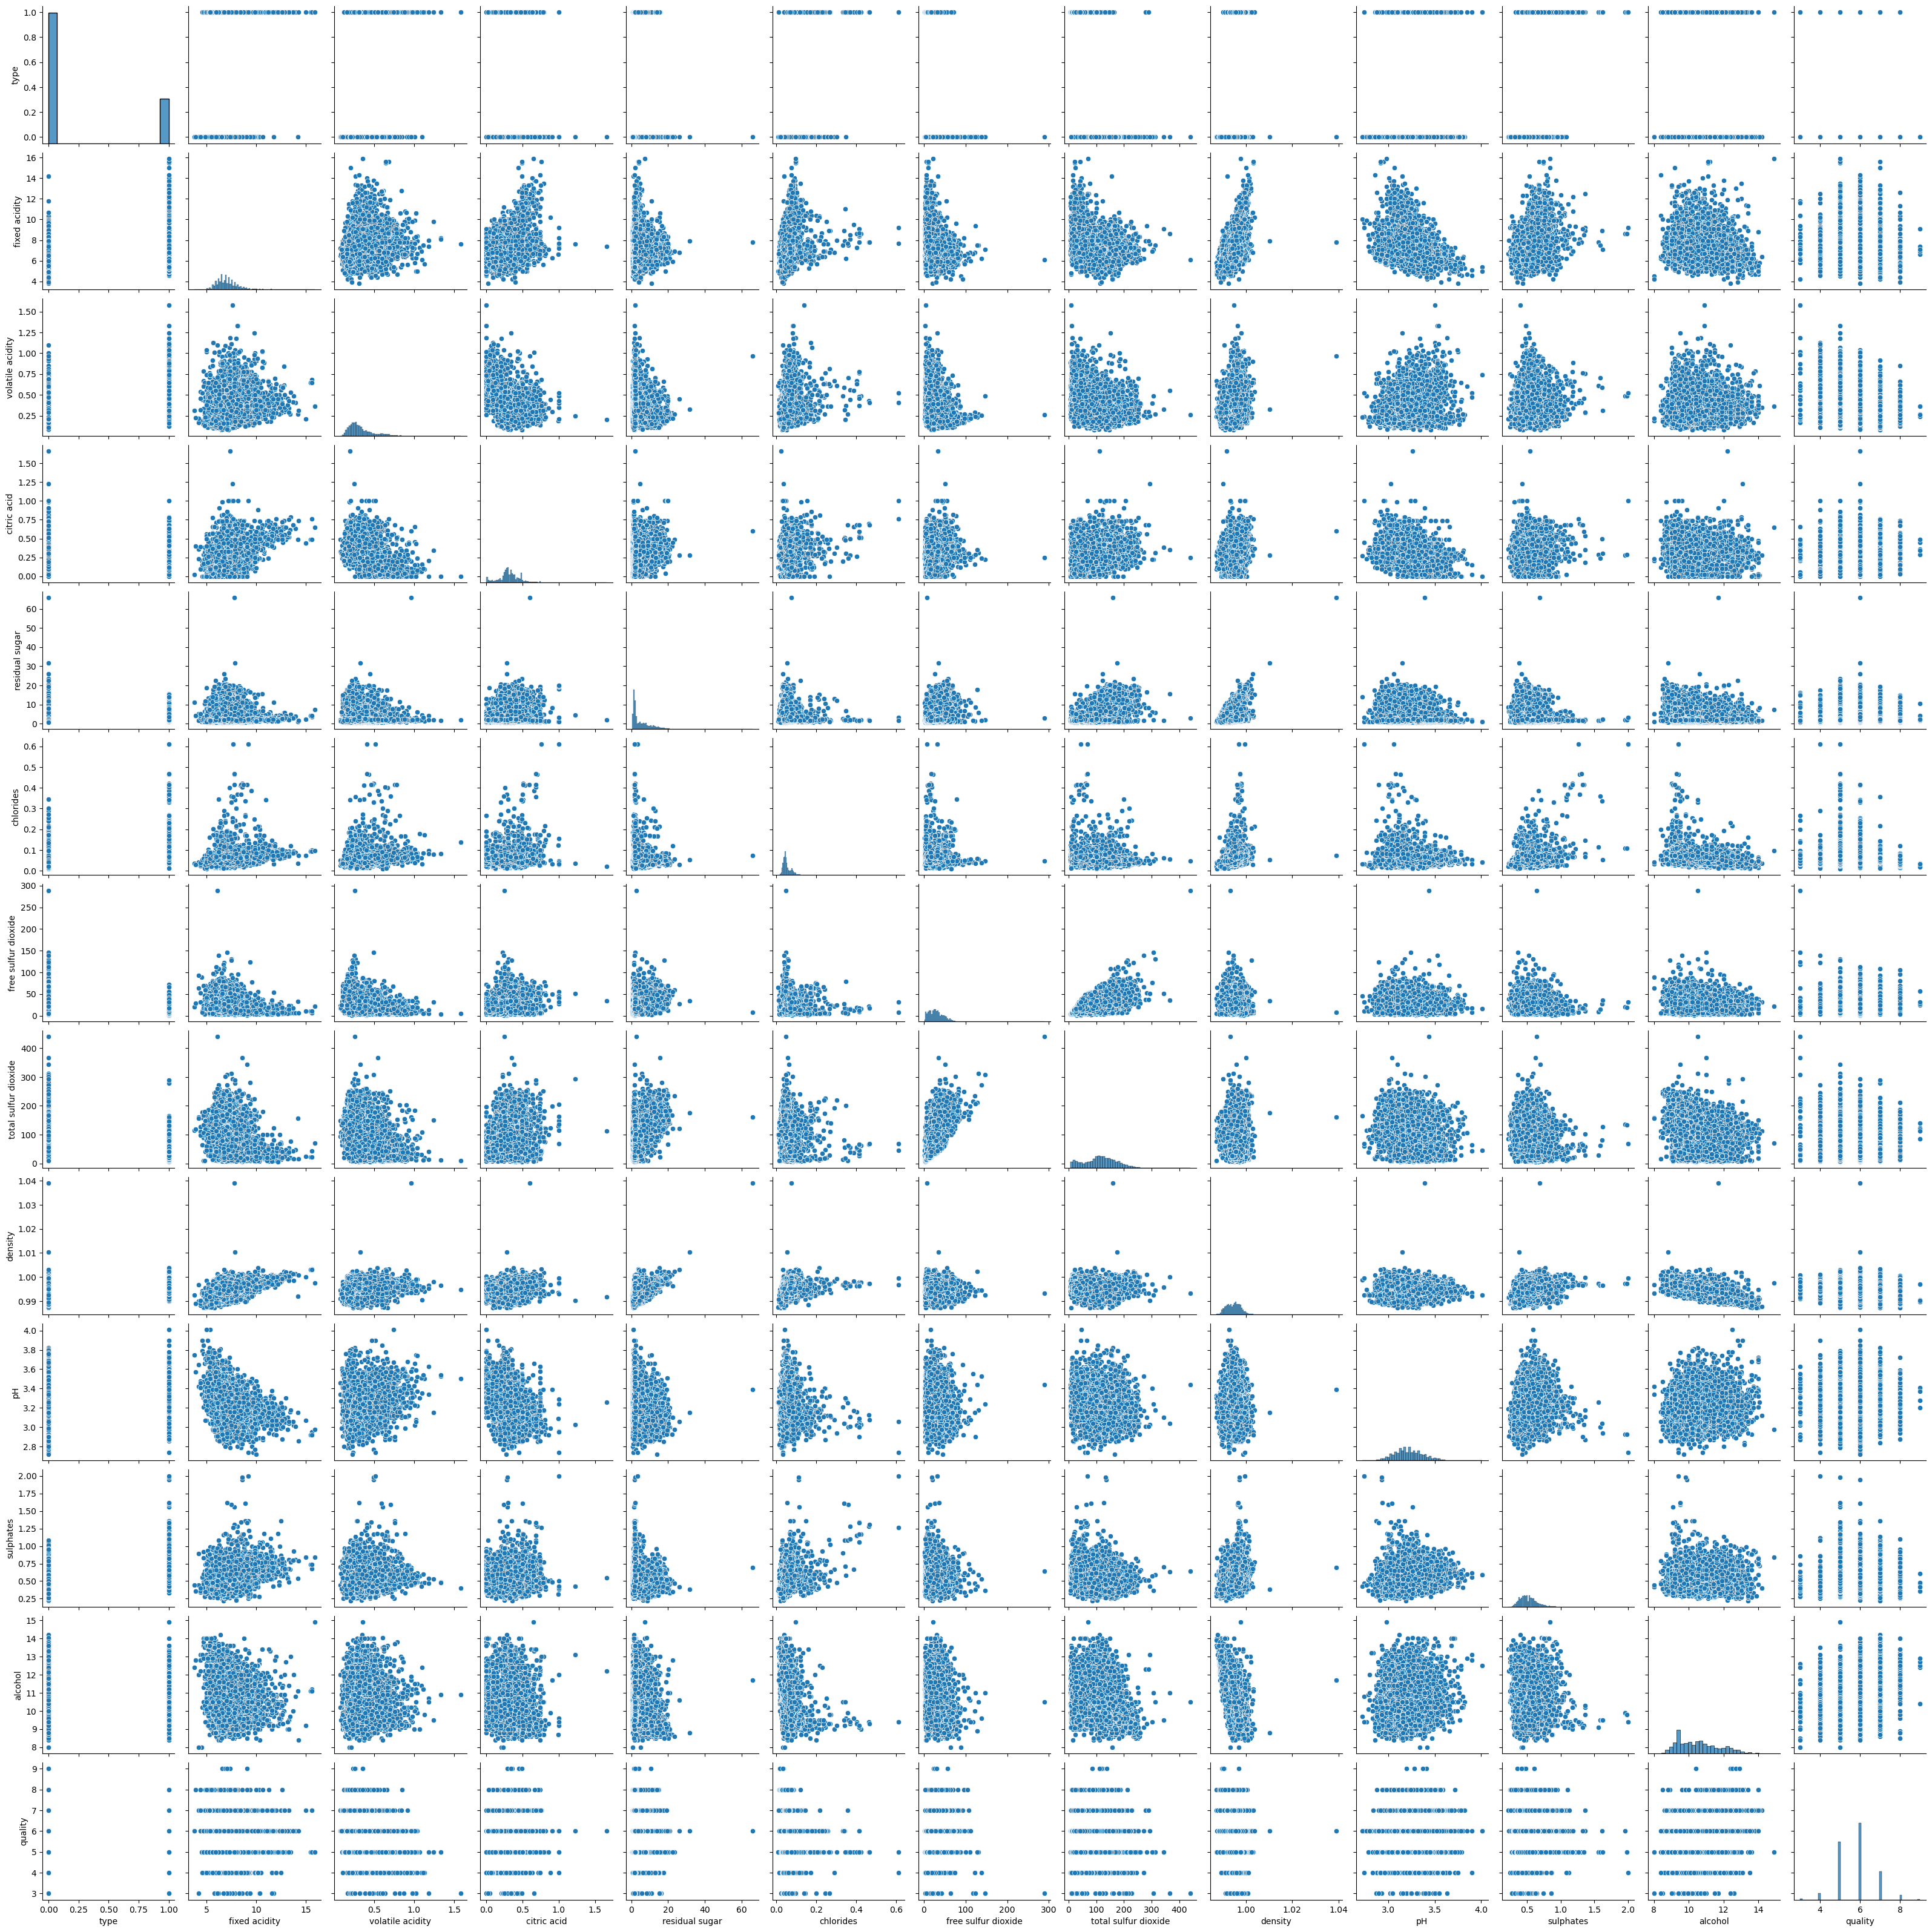

In [17]:
disp = sns.pairplot(df)

##**Identificar outliers**

Los valores atípicos son puntos de datos que difieren significativamente de otros puntos de datos y son inusuales. No sigue el patrón de todos los demás. Básicamente, llamamos a un dato un valor atípico porque la probabilidad de que un punto de datos tenga el valor que tiene el valor atípico es muy baja.

Podemos identificar los valores atípicos mediante diferentes métodos, a continuación usaremos dos de ellos para cada atributo.

In [ ]:
df.columns

###**Densidad**

<Axes: xlabel='None', ylabel='density'>

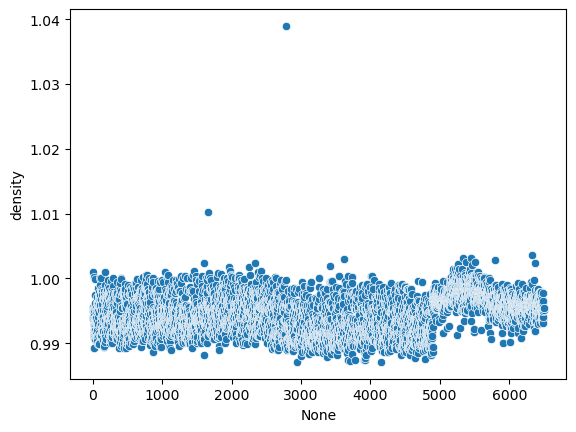

In [18]:
sns.scatterplot(data=df, x=df.index, y="density")

In [19]:
from scipy import stats

# Calcular el valor z
z = np.abs(stats.zscore(df['density']))

# Identificar los outliers
threshold = 3
outliers_dens = df[z > threshold]

outliers_dens.count()
#print(outliers_dens)

type                    3
fixed acidity           3
volatile acidity        3
citric acid             3
residual sugar          3
chlorides               3
free sulfur dioxide     3
total sulfur dioxide    3
density                 3
pH                      3
sulphates               3
alcohol                 3
quality                 3
dtype: int64

In [20]:
# Eliminar los outliers
df = df.drop(outliers_dens.index)
df = df.reset_index()
df = df.drop(columns=['index'])
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,0,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,0,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,0,6.2,0.320,0.16,7.0,0.045,30.0,136.0,0.99490,3.18,0.47,9.6,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5321,1,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
5322,1,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
5323,1,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
5324,1,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


Utilizar ML para identificar outliers

In [21]:
from sklearn.neighbors import LocalOutlierFactor

densidad = pd.DataFrame(df, columns=['density'])

# Identificar los outliers
out_densidad = LocalOutlierFactor(n_neighbors=100, algorithm='kd_tree',novelty=True)
out_densidad.fit(densidad)
out_densidad = out_densidad.predict(densidad)
out_densidad = pd.DataFrame(out_densidad, columns=['Outlier'])
out_densidad

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


,Outlier
0,-1
1,1
2,1
3,1
4,1
...,...
5321,1
5322,1
5323,1
5324,1


In [22]:
#Contar el número de outliers
out_densidad.loc[out_densidad['Outlier'] == -1].count()

Outlier    70
dtype: int64

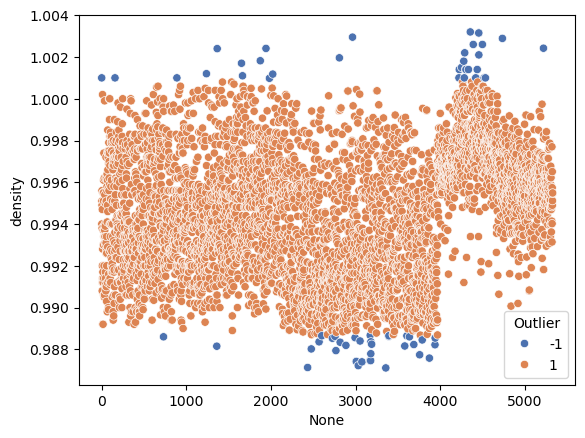

In [23]:
#Crear un diagrama de dispersión para ver los outliers
out_plot = sns.scatterplot(data=densidad, x=densidad.index, y='density', hue=out_densidad['Outlier'], palette="deep")

In [24]:
index_out = out_densidad.loc[out_densidad['Outlier'] == -1]

# Eliminar el resto de los outliers
df = df.drop(index_out.index)
df = df.reset_index()
df = df.drop(columns=['index'])
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
1,0,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
2,0,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
3,0,6.2,0.320,0.16,7.0,0.045,30.0,136.0,0.99490,3.18,0.47,9.6,6
4,0,8.1,0.220,0.43,1.5,0.044,28.0,129.0,0.99380,3.22,0.45,11.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5251,1,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
5252,1,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
5253,1,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
5254,1,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


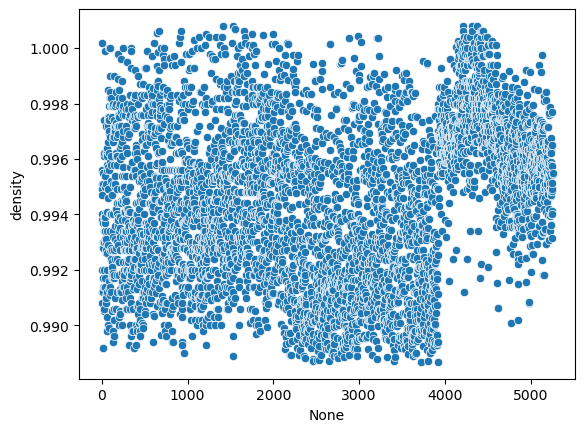

In [25]:
out_plot2 = sns.scatterplot(data=df, x=df.index, y='density')

In [ ]:
df.columns

Index(['Wine_type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='object')

###**Dióxido de azufre libre**

#**Conjunto Final**

In [ ]:
df.describe()

In [ ]:
disp = sns.pairplot(df)

#**Correlación entre variables**

Construir la matriz de correlación de las variables.

In [26]:
df.corr()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
type,1.000000,0.479052,0.646335,-0.194516,-0.342328,0.495699,-0.466518,-0.697560,0.437960,0.315236,0.484900,-0.051104,-0.112492
fixed acidity,0.479052,1.000000,0.208286,0.318289,-0.123670,0.279485,-0.282896,-0.330734,0.466009,-0.272162,0.295392,-0.092745,-0.077163
volatile acidity,0.646335,0.208286,1.000000,-0.393421,-0.180750,0.366093,-0.349878,-0.403978,0.306461,0.248067,0.220982,-0.070328,-0.266073
citric acid,-0.194516,0.318289,-0.393421,1.000000,0.142107,0.048088,0.136803,0.198874,0.075227,-0.342035,0.053276,-0.000455,0.101531
residual sugar,-0.342328,-0.123670,-0.180750,0.142107,1.000000,-0.136370,0.410721,0.494644,0.492942,-0.240381,-0.186427,-0.301706,-0.051570
chlorides,0.495699,0.279485,0.366093,0.048088,-0.136370,1.000000,-0.189449,-0.271837,0.373191,0.026891,0.401025,-0.266732,-0.199886
free sulfur dioxide,-0.466518,-0.282896,-0.349878,0.136803,0.410721,-0.189449,1.000000,0.720653,0.009249,-0.144375,-0.198166,-0.168925,0.058136
total sulfur dioxide,-0.697560,-0.330734,-0.403978,0.198874,0.494644,-0.271837,0.720653,1.000000,0.000305,-0.225779,-0.276771,-0.247008,-0.047855
density,0.437960,0.466009,0.306461,0.075227,0.492942,0.373191,0.009249,0.000305,1.000000,0.040129,0.278951,-0.684540,-0.333205
pH,0.315236,-0.272162,0.248067,-0.342035,-0.240381,0.026891,-0.144375,-0.225779,0.040129,1.000000,0.170081,0.100648,0.042651


<Axes: >

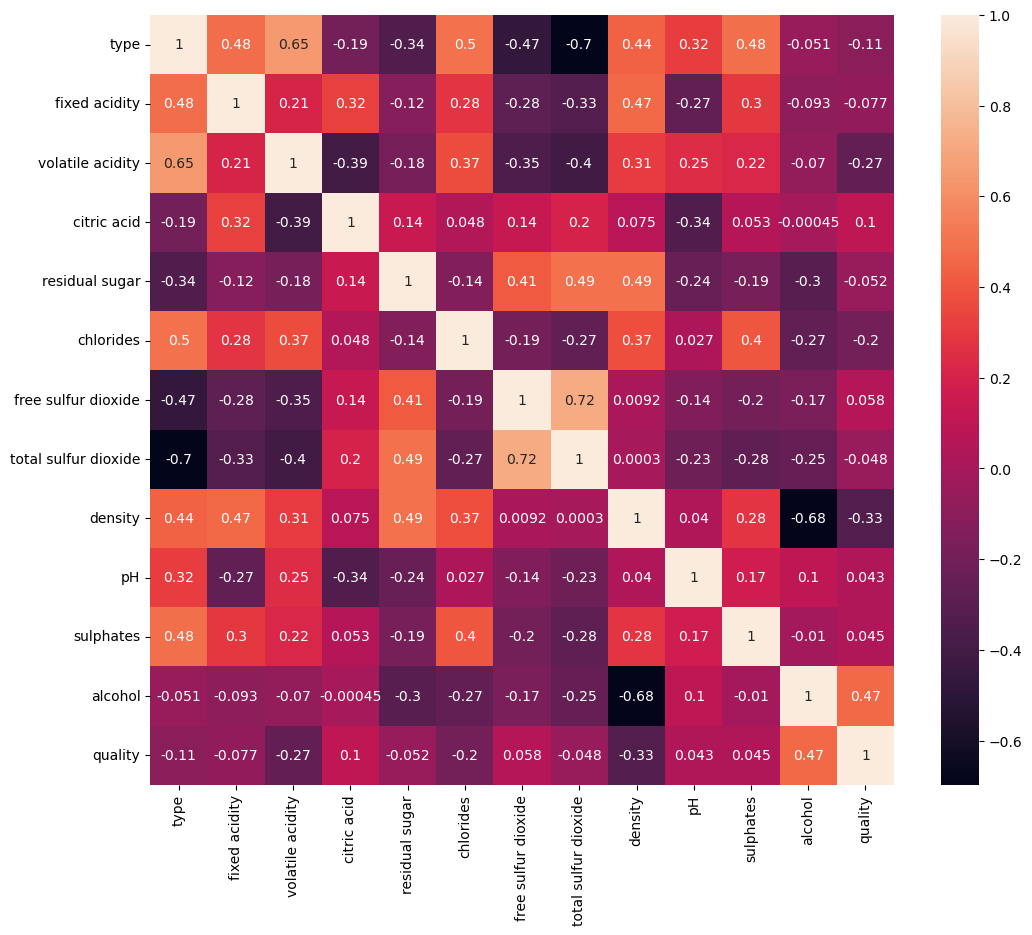

In [27]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True )

In [28]:
corr_target= df.corrwith(df["quality"])
corr_target = corr_target.sort_values(ascending=False)
corr_target

quality                 1.000000
alcohol                 0.467708
citric acid             0.101531
free sulfur dioxide     0.058136
sulphates               0.044898
pH                      0.042651
total sulfur dioxide   -0.047855
residual sugar         -0.051570
fixed acidity          -0.077163
type                   -0.112492
chlorides              -0.199886
volatile acidity       -0.266073
density                -0.333205
dtype: float64